# 01b — The DECAL detector and a single PION event

This is the **pion (pi+) sibling** of [`01_detector_and_data.ipynb`](01_detector_and_data.ipynb).
It repeats the *same* steps on the detector and its data — open one simulation
file, parse the geometry that *quantizes* every event into 100 µm pixels, watch a
single event land on that geometry, and make the same first-look plots — but the
primary is a **charged pion (pi⁺)** instead of a photon. **Run both and compare
your plots side by side**: the photon-vs-pion contrast is the whole point.

DECAL = **D**igital **E**lectromagnetic **CAL**orimeter: the silicon is finely
pixelated (100 µm) and each pixel is essentially a *yes/no* hit. Counting hits ≈
counting particles — until the shower gets so dense that pixels saturate.

**Why a pion looks different.** This detector is an **electromagnetic** Si–W
calorimeter: ~25 radiation lengths (X₀) deep, but only ~1 nuclear
interaction length (λ_I) — both budgets are computed from the geometry in
[`01_detector_and_data.ipynb`](01_detector_and_data.ipynb) §3b. A photon converts and builds a clean, compact
electromagnetic shower (pair-production + bremsstrahlung) that the ~25 X₀ fully
develop. A high-energy **pi⁺ usually does not** build a full hadronic shower in so
little λ_I. Two regimes dominate instead:

1. **MIP punch-through.** The pi⁺ traverses the stack as a
   minimum-ionizing particle, leaving a thin, near-straight track of ~MIP hits —
   *very few* hits and *low* deposited energy. (For scale: a simulated 50 GeV
   pi⁺ leaves ~35 silicon crossings, versus ~3000 for a 50 GeV photon EM shower
   (notebook 08 prints the pion's crossings, notebooks 06 and 07 the photon's).)
   At the stack's 1.00 λ_I (notebook 01 §3b) about e⁻¹ ≈ 37% of pions do this; most interact.
2. **Early hadronic interaction.** In most events the pi⁺ undergoes a nuclear
   interaction in the tungsten, producing a messy, wide, irregular shower with a
   large electromagnetic sub-component from π⁰ → 2γ. Those π⁰ sub-showers locally
   look just like the photon showers in the sibling notebook.

The two cases, drawn: a pion that crosses every layer, and one that hits a nucleus part way in.

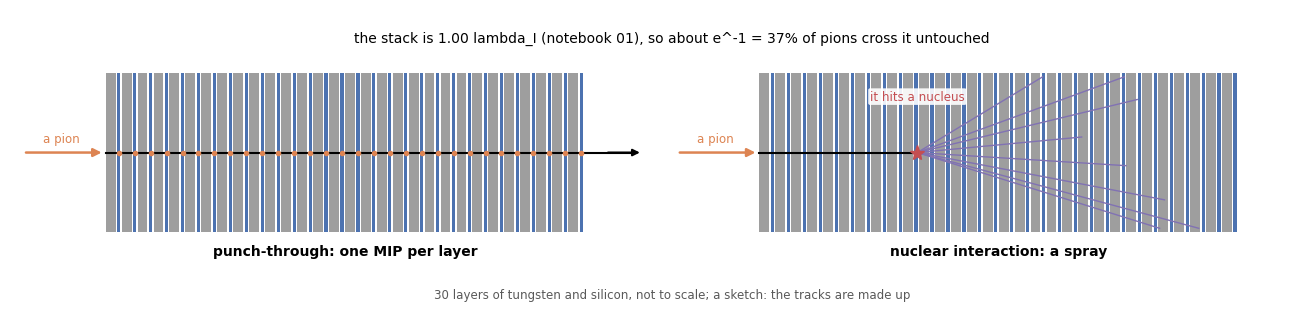

In [1]:
import os, sys
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath(os.path.join('..', 'analysis', 'pixelav')))
sys.path.insert(0, os.path.abspath(os.path.join('..', 'analysis')))
import sketches                  # drawn schematics, no data (analysis/pixelav/sketches.py)
import decal_geometry            # the layer stack of geometry/my_custom_ecal.xml

N_LAYERS = len(decal_geometry.layer_stack(os.path.abspath('..')))   # one entry per layer
sketches.pion_regimes(N_LAYERS)
plt.show()

The consequences you will *see* below, versus the photon notebook: far fewer hits
on average and **huge event-to-event fluctuation**; a **lower and highly variable**
sampling fraction (the photon's is a clean 1.48%, notebook 01 §8); a longitudinal profile that is
flat/sparse for punch-through and deep/late for an interacting pion; and a
transverse pattern that is often a single narrow MIP line rather than a compact EM
blob.

**Truth energy.** The pi⁺ is *massive* (m = 0.13957 GeV), so its true energy is
E = √(p² + m²), not |p|. The code computes this generically — it does not assume a
massless primary.

**Prerequisites**: `setup_calomaps.sh` sourced, and some **pi⁺** simulation data
present — the `..._piplus` dataset (see [`docs/handbook.md`](../docs/handbook.md)
§8; generate with `CALOMAPS_GUN_PARTICLE=pi+`).

**Kernel**: `Key4hep (CPU)` — no GPU needed.

Where this notebook sits in the series (its box is filled): it opens the ROOT files of the pion sample.

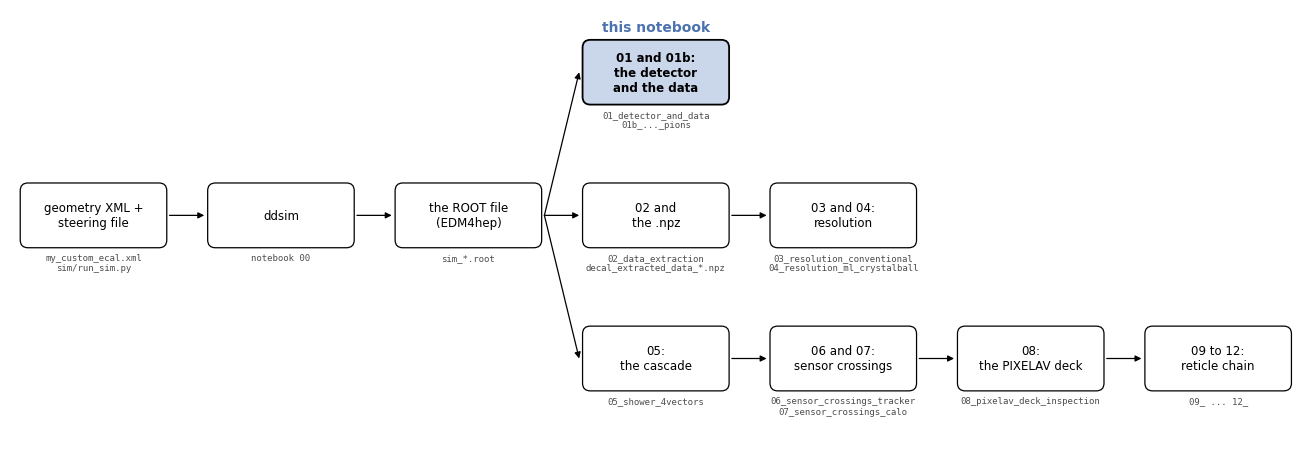

In [2]:
sketches.series_chain('01b')
plt.show()

## 1. Find a data file

In [3]:
import os
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

# CALOMAPS_DATA_BASE points to where simulation output lives (set by setup_calomaps.sh).
data_base = os.environ.get("CALOMAPS_DATA_BASE", os.path.expanduser("~/CALOMAPS-data"))
dataset_name = "data_spectrum_100um_400GeV_piplus"   # the pi+ production dataset
dataset_dir = os.path.join(data_base, dataset_name)

# Pick the first file
import glob
files = sorted(glob.glob(os.path.join(dataset_dir, "sim_piplus_part*.root")))
print(f"found {len(files)} files in {dataset_dir}")
print(f"opening first one: {files[0] if files else '(none — generate data first)'}")
filepath = files[0]


found 100 files in /home/murtazas/CALOMAPS-data/data_spectrum_100um_400GeV_piplus
opening first one: /home/murtazas/CALOMAPS-data/data_spectrum_100um_400GeV_piplus/sim_piplus_part1.root


## 2. What's inside the file?

The file is a ROOT file. Inside is a `TTree` named `events` (one entry per simulated event), with a flat list of branches that pack everything: truth-particle info, hit positions, hit energies, layer IDs, cell IDs, etc.

`uproot` lets us read these without depending on the C++ ROOT install.


In [4]:
with uproot.open(filepath) as f:
    print("top-level keys in the file:")
    for k in f.keys()[:8]:
        print(f"  {k}")
    print("...")
    tree = f["events"]
    print(f"\nevents.num_entries = {tree.num_entries}")
    print(f"number of branches  = {len(tree.keys())}")
    print(f"\nfirst 10 branches:")
    for k in tree.keys()[:10]:
        print(f"  {k}")


top-level keys in the file:
  events;1
  runs;1
  meta;1
  metadata;1
  podio_metadata;1
...

events.num_entries = 20
number of branches  = 68

first 10 branches:
  ECalBarrelHits
  ECalBarrelHits/ECalBarrelHits.cellID
  ECalBarrelHits/ECalBarrelHits.energy
  ECalBarrelHits/ECalBarrelHits.position.x
  ECalBarrelHits/ECalBarrelHits.position.y
  ECalBarrelHits/ECalBarrelHits.position.z
  ECalBarrelHits/ECalBarrelHits.contributions_begin
  ECalBarrelHits/ECalBarrelHits.contributions_end
  _ECalBarrelHits_contributions
  _ECalBarrelHits_contributions/_ECalBarrelHits_contributions.index


## 3. The detector geometry — a *quantized* calorimeter

The ECal is a **12-sided silicon barrel** (a dodecagonal tube) whose axis runs
along **z**. Through its depth (the radial direction; the code calls it y, the depth on the
+y face the beam enters) it is a sandwich of **30 silicon sensor layers** interleaved
with tungsten absorber, between r = 1264 mm (inner face) and r = 1403 mm. Two
kinds of quantization define a DECAL:

- **Transverse**: each layer is tiled into **100 µm pixels** — the spatial quantum.
  A hit is a *pixel*, not a continuous position.
- **Longitudinal**: the shower is sampled at **30 discrete depths** (the layers).

We parse the layer depths straight out of the geometry XML below, and reuse them
to overlay the detector on the data.

In [5]:
import os, glob, xml.etree.ElementTree as ET
import uproot, awkward as ak, numpy as np, matplotlib.pyplot as plt

# Resolve the repo root. Prefer $CALOMAPS_HOME (exported by `source setup_calomaps.sh`
# in a terminal); otherwise auto-locate it by walking up from the kernel's working
# directory, so the notebook also works when opened from the JupyterLab GUI — whose
# kernel does NOT inherit a terminal's environment.
def _calomaps_home():
    h = os.environ.get("CALOMAPS_HOME")
    if h and os.path.isdir(os.path.join(h, "geometry")):
        return h
    p = os.path.abspath(os.getcwd())
    while p != os.path.dirname(p):
        if os.path.isdir(os.path.join(p, "geometry")) and os.path.isdir(os.path.join(p, "sim")):
            return p
        p = os.path.dirname(p)
    return os.path.expanduser("~/CALOMAPS")
CALOMAPS_HOME = _calomaps_home()
DATA_BASE = os.environ.get("CALOMAPS_DATA_BASE", os.path.expanduser("~/CALOMAPS-data"))

def parse_sid_value(v, constants):
    if not v: return 0.0
    if v in constants: return parse_sid_value(constants[v], constants)
    s = v.replace('*', ' * ').replace('cm', '10').replace('mm', '1')
    try: return eval(s, {"__builtins__": None}, {})
    except: return float(v)

geom_dir = os.path.join(CALOMAPS_HOME, "geometry")
main_xml = ET.parse(os.path.join(geom_dir, "SiD_TestBeam.xml")).getroot()
consts = {c.get("name"): c.get("value") for c in main_xml.findall(".//constant")}
custom_xml = ET.parse(os.path.join(geom_dir, "my_custom_ecal.xml")).getroot()
det = custom_xml.find(".//detector[@name='ECalBarrel']")

rmin = parse_sid_value(det.find("dimensions").get("rmin"), consts)
print(f"Detector face (rmin): {rmin:.2f} mm")

sensor_y_planes = []
curr_y = rmin
for layer in det.findall("layer"):
    rep = int(layer.get("repeat", 1))
    slices = layer.findall("slice")
    thick = sum(parse_sid_value(s.get("thickness"), consts) for s in slices)
    si_off = 0
    off = 0
    for s in slices:
        t = parse_sid_value(s.get("thickness"), consts)
        if s.get("material") == "Silicon":
            si_off = off + t / 2.0
        off += t
    for _ in range(rep):
        sensor_y_planes.append(curr_y + si_off)
        curr_y += thick

print(f"Total silicon layers: {len(sensor_y_planes)}")
print(f"First 5 layers at y = {[f'{y:.2f}' for y in sensor_y_planes[:5]]} mm")
print(f"Last 5 layers at y  = {[f'{y:.2f}' for y in sensor_y_planes[-5:]]} mm")


Detector face (rmin): 1264.00 mm
Total silicon layers: 30
First 5 layers at y = ['1266.91', '1270.66', '1274.41', '1278.16', '1281.91'] mm
Last 5 layers at y  = ['1375.66', '1381.91', '1388.16', '1394.41', '1400.66'] mm


## 4. Look at a single event

Each event is one **pi⁺** fired from the origin in **+y**. Unlike the photon — which
reliably showers in the silicon — this pi⁺ either **punches through as a MIP**
(a thin track, very few hits) or undergoes an early **hadronic interaction**
(a wide, irregular deposit). The hit collection is *jagged* (a different number of
hits per event, and the spread is far larger than for photons); `awkward` handles
that. Pull the first event's hits and compute the truth energy.

> **What to expect:** the hit count below is likely **much smaller** than the
> photon sibling's for a comparable energy, and it will swing wildly from event to
> event. Re-run on a few files (or look at the aggregates in section 8) to feel the
> fluctuation.

The printed contrast line compares the hit count with a punch-through, which leaves only tens
of hits. Event 0 of this file is not one: its count, printed below, is in the thousands.

*Try it:* set `filepath = files[3]` (or another index) at the end of the first code cell and run
sections 4 to 6 again; watch the hit count: tens means a punch-through, thousands an interaction.

In [6]:
with uproot.open(filepath) as f:
    tree = f["events"]
    # Read the first event only
    x = tree["ECalBarrelHits/ECalBarrelHits.position.x"].array(entry_stop=1)[0]
    y = tree["ECalBarrelHits/ECalBarrelHits.position.y"].array(entry_stop=1)[0]
    z = tree["ECalBarrelHits/ECalBarrelHits.position.z"].array(entry_stop=1)[0]
    e = tree["ECalBarrelHits/ECalBarrelHits.energy"].array(entry_stop=1)[0]
    # Truth particle: the pi+ beam is fired in +y, so |p| = momentum.y.
    p_mc = tree["MCParticles/MCParticles.momentum.y"].array(entry_stop=1)[0]
    p = float(p_mc[0])
    # The pi+ is MASSIVE: true energy = sqrt(p^2 + m^2), not |p| (m = 0.13957 GeV).
    PI_MASS = 0.13957  # GeV, charged pion
    e_true = (p**2 + PI_MASS**2) ** 0.5
    print(f"Event 0:")
    print(f"  truth pi+ momentum.y (= |p| for a +Y beam): {p:.2f} GeV")
    print(f"  truth pi+ energy  E = sqrt(p^2 + m^2):       {e_true:.2f} GeV   (m_pi = {PI_MASS} GeV)")
    print(f"  number of pixel hits: {len(x)}")
    _kind = ("an interacting pion" if len(x) >= 1000 else
             "a MIP punch-through" if len(x) < 100 else "between the two cases")
    print(f"    (a MIP punch-through pi+ leaves only tens of hits in the stack, a photon shower at this")
    print(f"     energy thousands; with {len(x)} hits this event is {_kind})")
    print(f"  hit x range:  [{ak.min(x):.1f}, {ak.max(x):.1f}] mm")
    print(f"  hit y range:  [{ak.min(y):.1f}, {ak.max(y):.1f}] mm   (entry face spans +1264..+1403; a large NEGATIVE min is cross-cavity leakage on the -y side)")
    print(f"  hit z range:  [{ak.min(z):.1f}, {ak.max(z):.1f}] mm")
    print(f"  hit energy range: [{ak.min(e)*1e6:.2f}, {ak.max(e)*1e6:.0f}] keV")
    print(f"  total visible E: {float(ak.sum(e)):.4f} GeV   (visible/true = the sampling fraction; measured in section 8)")

Event 0:
  truth pi+ momentum.y (= |p| for a +Y beam): 398.40 GeV
  truth pi+ energy  E = sqrt(p^2 + m^2):       398.40 GeV   (m_pi = 0.13957 GeV)
  number of pixel hits: 79
    (a MIP punch-through pi+ leaves only tens of hits in the stack, a photon shower at this
     energy thousands; with 79 hits this event is a MIP punch-through)
  hit x range:  [-31.8, 5.6] mm
  hit y range:  [1267.0, 1400.8] mm   (entry face spans +1264..+1403; a large NEGATIVE min is cross-cavity leakage on the -y side)
  hit z range:  [-3.1, 14.7] mm
  hit energy range: [0.81, 424] keV
  total visible E: 0.0072 GeV   (visible/true = the sampling fraction; measured in section 8)


## 5. Visualize the event on the detector

The natural way to *see the whole detector* is the **transverse plane (x–y)** —
perpendicular to the beam axis — where the full 12-sided ring is visible. The
pi⁺ travels **outward from the origin** and enters the **inner** face
(r = 1264 mm).

Two views:
1. **Transverse cross-section (x–y)** — the whole barrel ring. Most hits land on
   the +y entry face, but a single shower isn't fully contained: soft secondaries
   leak across the inner air cavity and strike the other faces too — which is why
   hits appear all the way around the ring.
2. **Zoom on the +y entry face** — the same plane, with the 30 silicon layers
   drawn. Up the panel is deeper into the stack, so this is where the shower develops
   layer by layer.

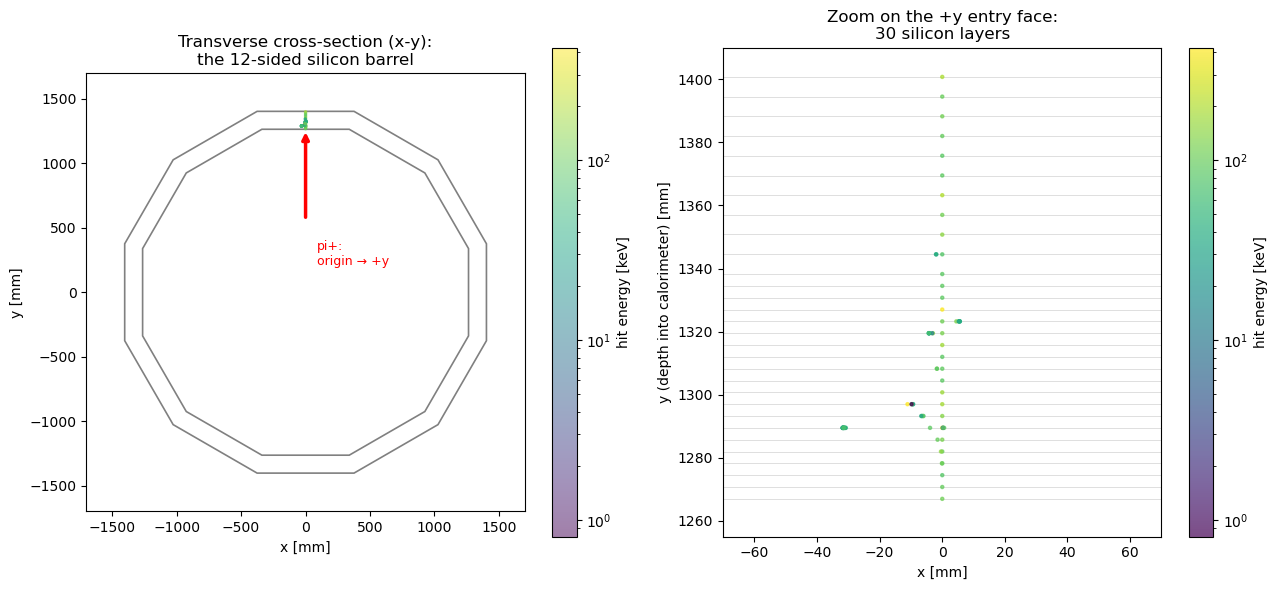

Left: the whole event in the barrel cross-section; with 79 hits this event is a MIP punch-through. A MIP punch-through pi+ is a sparse, narrow track on the +y face; an interacting pi+ is wider and patchier.
Right: zoomed to the entry face; the 30 horizontal lines are the silicon sensor layers the pi+ crosses (a near-vertical line of hits would be a clean MIP punch-through; this event is a MIP punch-through).


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import RegularPolygon

x_np = ak.to_numpy(x); y_np = ak.to_numpy(y); z_np = ak.to_numpy(z)
e_keV = ak.to_numpy(e) * 1e6   # GeV -> keV for the colour scale

# Barrel geometry (from geometry/SiD_TestBeam.xml): 12-sided, r = 1264..1403 mm,
# axis along z. The ring therefore lives in the x-y plane.
NSIDES, RMIN, RMAX = 12, 1264.0, 1403.0

def dodecagon(apothem):
    # RegularPolygon wants the circumradius (centre->vertex) = apothem / cos(pi/n);
    # rotate by pi/n so a flat FACE (not a vertex) points +y, matching the entry face.
    return RegularPolygon((0, 0), numVertices=NSIDES,
                          radius=apothem / np.cos(np.pi / NSIDES),
                          orientation=np.pi / NSIDES,
                          fill=False, edgecolor="0.5", lw=1.2)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Panel 1 — full transverse ring (x-y), all hits + the 12-sided silicon shell
ax = axes[0]
ax.add_patch(dodecagon(RMIN)); ax.add_patch(dodecagon(RMAX))
sc = ax.scatter(x_np, y_np, c=e_keV, cmap="viridis", s=2, alpha=0.5, norm=LogNorm())
# pi+ starts at the ORIGIN and travels +y outward, entering the INNER face
ax.annotate("", xy=(0, RMIN), xytext=(0, 560),
            arrowprops=dict(arrowstyle="-|>", color="red", lw=2.5))
ax.text(90, 300, "pi+:\norigin → +y", color="red", fontsize=9, va="center")
ax.set_aspect("equal"); ax.set_xlim(-1700, 1700); ax.set_ylim(-1700, 1700)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
ax.set_title("Transverse cross-section (x-y):\nthe 12-sided silicon barrel")
fig.colorbar(sc, ax=ax, label="hit energy [keV]")

# Panel 2 — zoom on the +y entry face, with the silicon layers as lines
ax = axes[1]
face = (y_np > 1240) & (np.abs(x_np) < 70)
layer_y = np.unique(np.round(y_np[face], 1))
for ly in layer_y:
    ax.axhline(ly, color="0.85", lw=0.6, zorder=0)
sc2 = ax.scatter(x_np[face], y_np[face], c=e_keV[face], cmap="viridis", s=5,
                 alpha=0.7, norm=LogNorm())
ax.set_xlim(-70, 70); ax.set_ylim(1255, 1410)
ax.set_xlabel("x [mm]"); ax.set_ylabel("y (depth into calorimeter) [mm]")
ax.set_title(f"Zoom on the +y entry face:\n{len(layer_y)} silicon layers")
fig.colorbar(sc2, ax=ax, label="hit energy [keV]")

plt.tight_layout()
plt.show()
print(f"Left: the whole event in the barrel cross-section; with {len(x_np)} hits this event is {_kind}. "
      f"A MIP punch-through pi+ is a sparse, narrow track on the +y face; an interacting pi+ is "
      f"wider and patchier.")
print(f"Right: zoomed to the entry face; the {len(layer_y)} horizontal lines are the "
      f"silicon sensor layers the pi+ crosses (a near-vertical line of hits would be a clean "
      f"MIP punch-through; this event is {_kind}).")

## 6. How the event develops through the detector

Now follow this one pi⁺ *into* the calorimeter. We keep the +y entry segment,
assign every hit to its silicon layer (by its depth), and look at three views:

1. **One layer at 100 µm resolution** — zoom into the densest layer so the
   individual pixels are visible. This *is* the quantization: each lit square is
   a 100 µm × 100 µm yes/no pixel. For a MIP track this is just a *handful* of
   pixels (the track's footprint), not the dense core a photon paints.
2. **Layer-by-layer evolution** — the transverse hit pattern in all 30 layers.
   A punch-through pi⁺ shows a *roughly constant, sparse* spot at nearly the same
   (x, z) in every layer (a straight track seen edge-on); an interacting pi⁺
   shows hits suddenly fanning out at the interaction depth and then a ragged,
   late development — not the smooth narrow→shower-max→fade of a photon.
   What to see in this event: a few scattered hits in the first layers, then a wide spray
   that switches on part way in and fills every later layer (the colour scale is set by the
   hottest hit, so most points look black; only their positions matter here).
3. **Longitudinal profile** — total energy per layer vs depth for this single
   event. Expect it to be **flat and low** for punch-through, or to **switch on
   late** at the interaction point — contrast with the photon's smooth early peak
   (compare to the energy-averaged version in `02_data_extraction`).

In [8]:
import numpy as np
e_np = ak.to_numpy(e)                       # this event's hit energies (GeV)
RADII = np.array(sensor_y_planes)           # 30 silicon layer depths from the XML

# the +y entry face is a flat facet -> Si layers sit at CONSTANT y; index the
# layer by depth y (not the z-axis radius hypot(x,y)).
ang  = np.degrees(np.arctan2(x_np, y_np))
seg  = (np.abs(ang) < 15) & (y_np > 1260) & (y_np < 1410)
xs, zs, es, ys = x_np[seg], z_np[seg], e_np[seg], y_np[seg]
lyr = np.argmin(np.abs(RADII[None, :] - ys[:, None]), axis=1)
print(f"{seg.sum()} hits in the +y segment, spread over {len(np.unique(lyr))} layers")

79 hits in the +y segment, spread over 30 layers


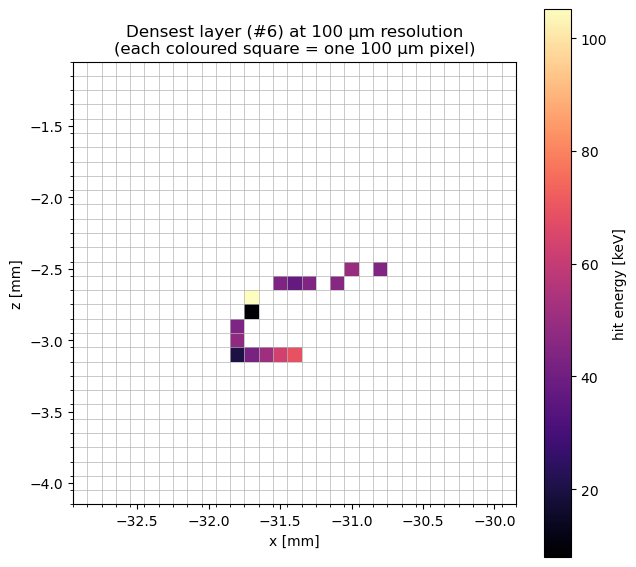

In [9]:
# 1. One layer at 100 um resolution -- the pixelization, made visible.
# Render real pixel CELLS (pcolormesh on the integer pixel grid) so each lit
# pixel is exactly one 100 um grid square, neatly aligned to the gridlines.
PITCH = 0.1
dense = np.bincount(lyr, minlength=len(RADII)).argmax()
m = lyr == dense
xi = np.round(xs[m] / PITCH).astype(int)
zi = np.round(zs[m] / PITCH).astype(int)
ei = es[m] * 1e6                                   # keV
ci_x, ci_z, half = int(np.median(xi)), int(np.median(zi)), 15   # +-15 px = +-1.5 mm
nx = nz = 2 * half + 1
img = np.full((nz, nx), np.nan)
for ix, iz, ee in zip(xi, zi, ei):
    jx, jz = ix - (ci_x - half), iz - (ci_z - half)
    if 0 <= jx < nx and 0 <= jz < nz:
        img[jz, jx] = ee if np.isnan(img[jz, jx]) else img[jz, jx] + ee
# cell EDGES in mm -> every coloured square spans exactly one 100 um pixel
xed = (np.arange(ci_x - half, ci_x + half + 2) - 0.5) * PITCH
zed = (np.arange(ci_z - half, ci_z + half + 2) - 0.5) * PITCH

fig, ax = plt.subplots(figsize=(6.5, 6))
pcm = ax.pcolormesh(xed, zed, img, cmap="magma")
ax.set_xticks(xed, minor=True); ax.set_yticks(zed, minor=True)
ax.grid(which="minor", color="0.7", lw=0.5)
ax.set_aspect("equal")
ax.set_xlabel("x [mm]"); ax.set_ylabel("z [mm]")
ax.set_title(f"Densest layer (#{dense}) at 100 µm resolution\n(each coloured square = one 100 µm pixel)")
fig.colorbar(pcm, ax=ax, label="hit energy [keV]")
plt.tight_layout(); plt.show()

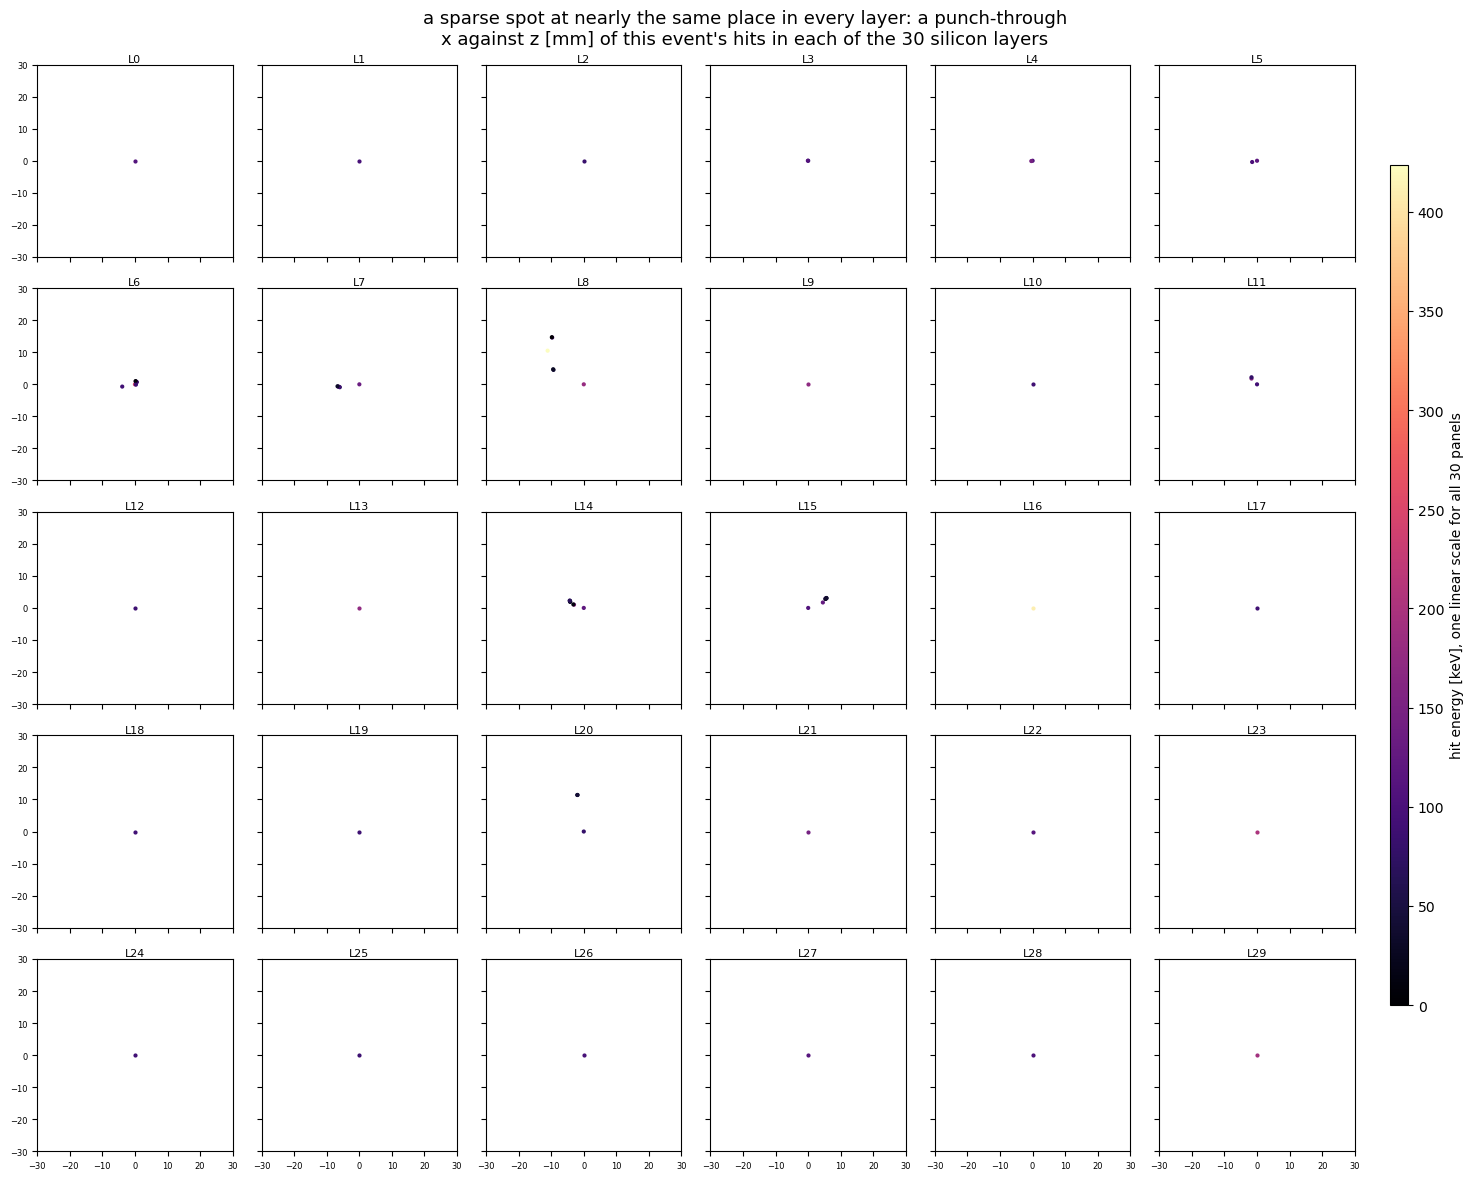

In [10]:
# 2. Transverse shower evolution, layer by layer
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
nlayers = len(RADII)
fig, axes = plt.subplots(5, 6, figsize=(15, 12), sharex=True, sharey=True)
vmax = (es * 1e6).max() if len(es) else 1.0
for i, ax in enumerate(axes.flat):
    if i >= nlayers:
        ax.axis("off"); continue
    m = lyr == i
    if m.any():
        ax.scatter(xs[m], zs[m], c=es[m] * 1e6, cmap="magma", s=4, vmin=0, vmax=vmax)
    ax.set_xlim(-30, 30); ax.set_ylim(-30, 30)
    ax.set_title(f"L{i}", fontsize=8, pad=2)
    ax.tick_params(labelsize=6)
_nl = np.bincount(lyr, minlength=nlayers)                              # hits per layer
_on = int(np.argmax(_nl > 10)) if (_nl > 10).any() else None           # first layer with more than 10 hits
if len(xs) >= 1000 and _on:
    _point = f"the deposit switches on at L{_on}, wide and patchy from there on: an interacting pion"
elif len(xs) >= 1000:
    _point = "the deposit is wide from L0 on: this pion interacted before the first layer"
else:
    _point = "a sparse spot at nearly the same place in every layer: a punch-through"
fig.suptitle(_point + f"\nx against z [mm] of this event's hits in each of the {nlayers} silicon layers", fontsize=13)
plt.tight_layout(rect=(0, 0, 0.92, 1))
# one bar for the panels' shared linear scale, 0 to the hottest hit of the event
cax = fig.add_axes([0.93, 0.15, 0.012, 0.7])
fig.colorbar(ScalarMappable(norm=Normalize(vmin=0, vmax=vmax), cmap="magma"), cax=cax,
             label=f"hit energy [keV], one linear scale for all {nlayers} panels")
plt.show()

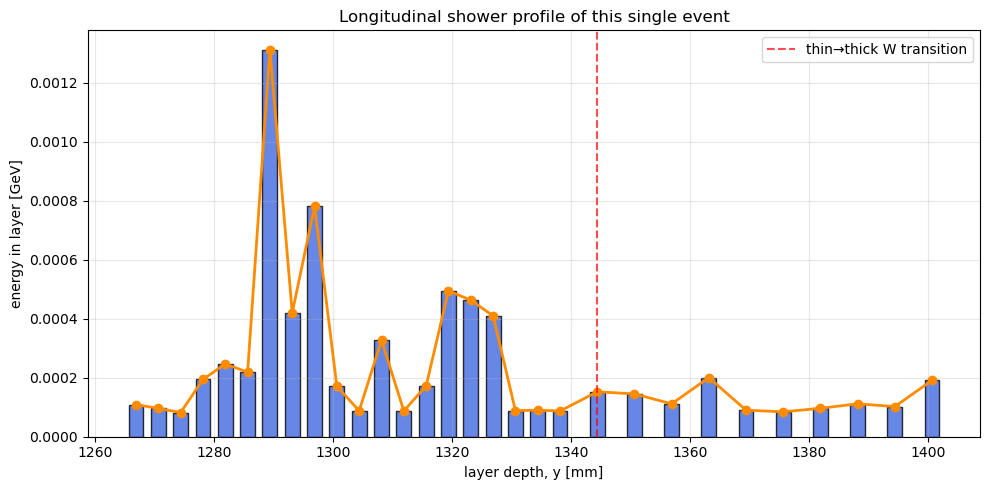

In [11]:
# 3. Longitudinal profile of this single event
le = np.bincount(lyr, weights=es, minlength=nlayers)[:nlayers]
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(RADII, le, width=2.5, color="royalblue", edgecolor="black", alpha=0.8)
ax.plot(RADII, le, color="darkorange", marker="o", lw=2)
if nlayers > 20:
    ax.axvline(RADII[20], color="red", ls="--", alpha=0.7, label="thin→thick W transition")
    ax.legend()
ax.set_xlabel("layer depth, y [mm]"); ax.set_ylabel("energy in layer [GeV]")
ax.set_title("Longitudinal shower profile of this single event")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Reverse-engineer the geometry from the data

A nice sanity check: we should be able to *recover* the pixel pitch and the layer
count straight from the hit positions and confirm they match the XML — proving
the simulation quantizes the way we expect.

In [12]:
files = sorted(glob.glob(os.path.join(DATA_BASE, "data_spectrum_100um_400GeV_piplus", "sim_piplus_part*.root")))
filepath = files[0]
print(f"opening {filepath}")

with uproot.open(filepath) as f:
    tree = f["events"]
    x_j = tree["ECalBarrelHits/ECalBarrelHits.position.x"].array()
    y_j = tree["ECalBarrelHits/ECalBarrelHits.position.y"].array()
    z_j = tree["ECalBarrelHits/ECalBarrelHits.position.z"].array()

x_all = ak.flatten(x_j).to_numpy()
y_all = ak.flatten(y_j).to_numpy()
z_all = ak.flatten(z_j).to_numpy()

# Filter to the +Y face only (where the pi+ beam enters)
mask = (np.abs(x_all) <= 50) & (np.abs(z_all) <= 50) & (y_all >= 1260) & (y_all <= 1410)
x, y, z = x_all[mask], y_all[mask], z_all[mask]
print(f"Total hits in file:        {len(x_all)}")
print(f"Hits in +Y target volume:  {len(x)}")


opening /home/murtazas/CALOMAPS-data/data_spectrum_100um_400GeV_piplus/sim_piplus_part1.root
Total hits in file:        85653
Hits in +Y target volume:  77039


In [13]:
unique_x = np.unique(np.round(x, 4))
unique_y = np.unique(np.round(y, 4))
unique_z = np.unique(np.round(z, 4))

dx = np.diff(unique_x)
dz = np.diff(unique_z)
pitch_x = np.min(dx[dx > 0]) if len(dx) > 0 else 0
pitch_z = np.min(dz[dz > 0]) if len(dz) > 0 else 0

print(f"Pixel X pitch (from data):  {pitch_x:.5f} mm    (expect 0.1 mm = 100 um)")
print(f"Pixel Z pitch (from data):  {pitch_z:.5f} mm")
print(f"Sensor layers (from data):  {len(unique_y)}      (expect 30 from XML)")
_rad = np.array(sensor_y_planes)
_off = float(np.max(np.abs(_rad - unique_y[:len(_rad)])))
_halfpitch = float(np.median(np.diff(_rad)) / 2.0)
print(f"XML-vs-data layer-y max offset: {_off:.3f} mm  "
      f"({'within' if _off < _halfpitch else 'EXCEEDS'} {_halfpitch:.2f} mm, half the layer spacing "
      f"-> layer indexing {'unaffected' if _off < _halfpitch else 'BIASED'})")


Pixel X pitch (from data):  0.10000 mm    (expect 0.1 mm = 100 um)
Pixel Z pitch (from data):  0.10000 mm
Sensor layers (from data):  30      (expect 30 from XML)
XML-vs-data layer-y max offset: 0.100 mm  (within 1.88 mm, half the layer spacing -> layer indexing unaffected)


## 8. First-look aggregates

Finally, look across all events in this one file: how the digital (hit count) and
analog (visible energy) readouts grow with true energy, and what the **sampling
fraction** (visible/true) is for pions.

> **Expect a messier picture than for photons.** The hits-vs-E and visible-vs-E
> relations are far looser — many events sit *low* (MIP punch-through deposits only
> a sliver of energy), a few sit *high* (an early interaction dumps much more) — so
> the scatter is large and the trend is weak. The "sampling fraction" here is
> **not** the photon's clean, single-valued 1.48% (notebook 01 §8): it is **lower on average and
> highly variable**, because a pi⁺ deposits a *fraction* of one nuclear interaction
> length's worth of energy that itself fluctuates event to event. The straight-line
> fit below is a crude average, not the tight proportionality the photon shows.

> **Scope of this sampling fraction:** this first look sums **all** hits in the event (the whole 12-sided ring). Notebook 02 keeps only the **+y wedge**, so its visible-energy readout -- and the sampling fraction the resolution notebooks (03/04) work with -- is a smaller, wedge-restricted subset. The two are not directly comparable.

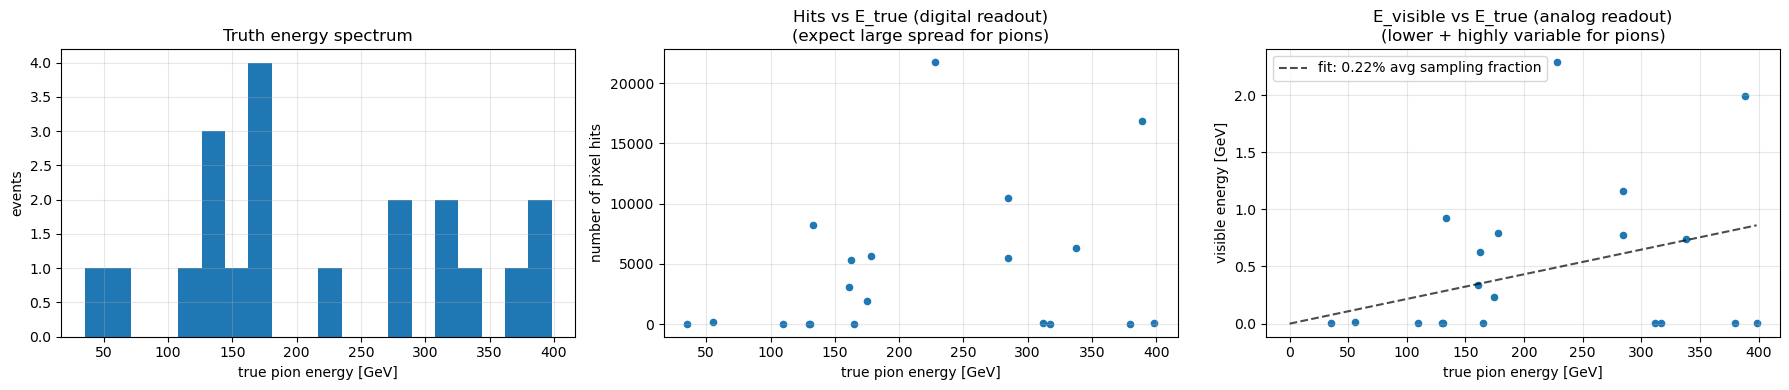

Note: compare these three panels with the photon sibling (notebook 01).
The photon's hits-vs-E and visible-vs-E are tight lines; the pion's are a
broad cloud with many low-deposit (punch-through) events.


In [14]:
with uproot.open(filepath) as f:
    tree = f["events"]
    x_all = tree["ECalBarrelHits/ECalBarrelHits.position.x"].array()
    e_all = tree["ECalBarrelHits/ECalBarrelHits.energy"].array()
    p_all = tree["MCParticles/MCParticles.momentum.y"].array()

hits_per_event = ak.num(x_all)
total_e_per_event = ak.sum(e_all, axis=1)
# The pi+ is MASSIVE: true energy = sqrt(p^2 + m^2), not |p| (m = 0.13957 GeV).
PI_MASS = 0.13957  # GeV, charged pion
p_per_event = ak.flatten(p_all)
true_e_per_event = np.sqrt(np.asarray(p_per_event, dtype=float) ** 2 + PI_MASS ** 2)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(true_e_per_event, bins=20)
axes[0].set_xlabel("true pion energy [GeV]")
axes[0].set_ylabel("events")
axes[0].set_title("Truth energy spectrum")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(true_e_per_event, hits_per_event, s=20)
axes[1].set_xlabel("true pion energy [GeV]")
axes[1].set_ylabel("number of pixel hits")
axes[1].set_title("Hits vs E_true (digital readout)\n(expect large spread for pions)")
axes[1].grid(True, alpha=0.3)

axes[2].scatter(true_e_per_event, total_e_per_event, s=20)
# For pions the visible/true ratio is NOT a clean constant: punch-through events
# deposit a sliver, early interactions deposit much more, so the points scatter
# widely. The through-origin fit below is therefore only a crude AVERAGE sampling
# fraction, not the tight proportionality a photon shows.
_t = np.asarray(true_e_per_event, dtype=float)
_v = np.asarray(total_e_per_event, dtype=float)
samp_frac = float(np.sum(_t * _v) / np.sum(_t * _t))
_xline = np.array([0.0, _t.max()])
axes[2].plot(_xline, samp_frac * _xline, "k--", alpha=0.7,
             label=f"fit: {samp_frac*100:.2f}% avg sampling fraction")
axes[2].set_xlabel("true pion energy [GeV]")
axes[2].set_ylabel("visible energy [GeV]")
axes[2].set_title("E_visible vs E_true (analog readout)\n(lower + highly variable for pions)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("Note: compare these three panels with the photon sibling (notebook 01).")
print("The photon's hits-vs-E and visible-vs-E are tight lines; the pion's are a")
print("broad cloud with many low-deposit (punch-through) events.")

## Photon vs pion, in one paragraph

The DECAL is a **quantized sampling calorimeter**: a 12-sided silicon barrel,
30 layers (~25 X₀) deep, every layer tiled into 100 µm yes/no pixels. But ~25 X₀
is only about **one** nuclear interaction length, so a pi⁺ fired in +y does
**not** reliably build a contained shower. The event shown here
**interacted**: 7375 pixel hits and a **wide, irregular** deposit on the entry face (§5, right
panel), where a punch-through leaves only tens of hits; an interacting pion's deposit carries
compact π⁰ → γγ sub-showers that look locally electromagnetic. If your event is a **MIP
punch-through** — a thin, sparse, near-straight track of hits crossing the layers
— you see that instead. Either way it is visibly
*unlike* the compact photon blob in the sibling notebook. Two physics threads run
through the rest of the project, both with a pion twist:

- **Sampling**: for a pi⁺ the visible-to-true fraction is **lower on average and
  highly variable** — punch-through deposits a sliver, an early interaction much
  more — rather than the photon's clean 1.48% (notebook 01 §8). That variability is a
  *hadronic* source of resolution loss on top of the usual stochastic term (the part of the
  resolution that falls as 1/√E, from counting fluctuations; notebook 03 measures it).
- **Quantization**: counting lit pixels (digital) still tracks energy, but the
  pion's enormous event-to-event fluctuation (and the fact that most of its energy
  may leave the calorimeter entirely) makes every readout noisier.

**Why we do *not* quote a pion energy resolution.** The photon notebooks go on to
measure σ_E/E two independent ways
([03](03_resolution_conventional.ipynb) and [04](04_resolution_ml_crystalball.ipynb)).
For pions in *this* detector that number is ill-defined: the response is **bimodal** —
a punch-through MIP peak plus an interacting tail — so a single Gaussian-core width
does not describe it (notebook 03 §9 discusses the breakdown). Measuring hadrons
properly needs a detector with several λ_I behind this one; the pion sample's job
here is the **contrast** with the photon.

**Compare with the photon sibling** ([`01_detector_and_data.ipynb`](01_detector_and_data.ipynb)):
put your section-6 per-layer slices, your longitudinal profile, and your section-8
aggregates next to the photon versions. The contrast — compact EM blob vs sparse
MIP track / ragged hadronic deposit — is the central lesson of this notebook.

**Notebook 02 asks the next question: how is each photon shower reduced to the handful of
numbers per event that the resolution notebooks use?**
